# WikiText-103 với SimpleRNN trong PyTorch

**Pipeline:** WikiText-103 → audit → vocabulary → token IDs → sequences → embedding → `nn.RNN` → linear logits → cross entropy → BPTT → gradient clipping → Adam → best validation checkpoint → test → top-1/top-5 → next-word prediction → temperature → autoregressive generation.

**Ngôn ngữ dữ liệu: tiếng Anh.** WikiText-103 không phải corpus tiếng Việt. Cấu trúc dự án: `data/` chứa cache dataset; `notebooks/` chứa notebook; `models/` chứa checkpoint và metadata cần cho API; `outputs/` chứa metrics, biểu đồ và kết quả sinh văn bản. Notebook này là demo word-level RNN cho web dự đoán từ tiếp theo; nó không thay thế notebook tiếng Việt trước đó. Mặc định chỉ dùng một phần **của WikiText-103 thực**, được ghi rõ trong báo cáo và checkpoint để chạy trên Anaconda/CPU. Chế độ toàn bộ cần nhiều RAM, dung lượng ổ đĩa và thời gian. Giao diện web có thể dùng checkpoint, từ vựng và JSON trả về từ các hàm cuối notebook.

## Cấu trúc thư mục dự án

```text
project/
├── data/                 # Hugging Face dataset cache
├── notebooks/            # File .ipynb này
├── models/               # best_rnn_state.pt, metadata.json
└── outputs/              # metrics.json, training_curves.png, topk_prediction.png, generation_sample.json
```

Đặt notebook trong `notebooks/`. Chạy các cell từ đầu; dữ liệu, mô hình và outputs được tạo tự động khi đến cell tương ứng.


## 1. Introduction to sequence data

Mỗi văn bản được biểu diễn thành chuỗi token `(w₁, w₂, …, wₜ)`. Language model ước lượng `P(wₜ₊₁ | w₁,…,wₜ)`. RNN dùng trạng thái ẩn để chuyển ngữ cảnh từ bước trước sang bước tiếp theo. Trong notebook này, mô hình tạo một dự đoán ở **mọi vị trí** của cửa sổ, thay vì chỉ dự đoán token cuối; điều đó dùng nhiều nhãn hơn trong mỗi lần cập nhật.

## 2. Dataset source

Nguồn: [Salesforce WikiText](https://huggingface.co/datasets/Salesforce/wikitext), cấu hình `wikitext-103-raw-v1`, có sẵn các split `train`, `validation`, `test`. Dùng các split gốc, **không tách validation/test từ train**. Đây là tập tiếng Anh lấy từ các bài Wikipedia chất lượng cao; phiên bản `raw` còn ký hiệu xử lý token như `@-@`. Dataset card ghi giấy phép CC BY-SA. Cần mạng để tải lần đầu và đủ bộ nhớ đệm. Đặt notebook trong `notebooks/`, rồi mở từ thư mục dự án. Các đường dẫn dưới đây tự tìm project root khi kernel bắt đầu trong `notebooks/` hoặc ngay project root. Cài trên đúng Jupyter kernel bằng `%pip install torch datasets numpy matplotlib ipywidgets` (PyTorch GPU theo hướng dẫn chính thức). Sau khi cài gói mới, restart kernel.

In [30]:
import sys, importlib.util
required=['torch','datasets','numpy','matplotlib']
missing=[name for name in required if importlib.util.find_spec(name) is None]
print('Kernel Python:',sys.executable)
if missing: raise ModuleNotFoundError('Thiếu '+', '.join(missing)+'. Chạy trong một cell: %pip install '+ ' '.join(missing)+' ; sau đó restart kernel.')
import re, json, math, random, unicodedata, collections, time
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
import torch
from torch import nn
from torch.utils.data import Dataset,DataLoader
from datasets import load_dataset
print('PyTorch:',torch.__version__)

Kernel Python: D:\Anaconda\python.exe
PyTorch: 2.14.0+cpu


In [31]:
SEED=42
DATASET='Salesforce/wikitext';CONFIG='wikitext-103-raw-v1'
# Dùng None cho split muốn đọc toàn bộ. Chế độ toàn bộ có thể rất chậm.
TOKEN_BUDGET={'train':2_000_000,'validation':200_000,'test':200_000}
VOCAB_SIZE=75_000;MIN_FREQ=2
SEQ_LEN=24;STRIDE=24
EMBED_DIM=96;HIDDEN_DIM=128;BATCH_SIZE=64
EPOCHS=5;LR=0.002;GRAD_CLIP=1.0;PATIENCE=2
MAX_ROWS_SCANNED=200_000
# Jupyter thường đặt cwd là notebooks/ khi mở file từ đó.
CWD=Path.cwd().resolve()
ROOT=CWD.parent if CWD.name.lower()=='notebooks' else CWD
DATA_DIR=ROOT/'data';MODELS_DIR=ROOT/'models';OUTPUTS_DIR=ROOT/'outputs'
for directory in (DATA_DIR,MODELS_DIR,OUTPUTS_DIR):directory.mkdir(parents=True,exist_ok=True)
print('Project root:',ROOT)
print('Dataset cache:',DATA_DIR,'| Checkpoints:',MODELS_DIR,'| Reports:',OUTPUTS_DIR)
random.seed(SEED);np.random.seed(SEED);torch.manual_seed(SEED)
if torch.cuda.is_available():torch.cuda.manual_seed_all(SEED)
device=torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('Device',device,'| token budgets',TOKEN_BUDGET)

Project root: C:\Users\ADMIN\Downloads\Intelligent System\RNN\DATA\Plus
Dataset cache: C:\Users\ADMIN\Downloads\Intelligent System\RNN\DATA\Plus\data | Checkpoints: C:\Users\ADMIN\Downloads\Intelligent System\RNN\DATA\Plus\models | Reports: C:\Users\ADMIN\Downloads\Intelligent System\RNN\DATA\Plus\outputs
Device cpu | token budgets {'train': 2000000, 'validation': 200000, 'test': 200000}


## 3. Text cleaning

Giữ dấu câu và số vì chúng là một phần của dự đoán ngôn ngữ; chỉ chuẩn hóa Unicode NFC, gộp khoảng trắng, chữ thường và bỏ những dòng chỉ chứa tiêu đề `= … =`. `wikitext-103-raw-v1` đã có khoảng trắng quanh nhiều dấu câu, nên tokenization ở đây dùng `split()` để rõ nguyên lý. Đây là lựa chọn demo: từ và dấu câu đôi khi được xem là một token chung, và không thể so sánh perplexity với benchmark WikiText-103 có tokenization khác.

In [32]:
def clean_line(line):
    line=unicodedata.normalize('NFC',str(line)).strip().lower()
    if not line or re.fullmatch(r'=+\s*[^=]+\s*=+',line):return ''
    return re.sub(r'\s+',' ',line)
def tokenize(line):return clean_line(line).split()
print(tokenize('The computer learned , but it made mistakes .'))

def fetch_split(split,budget):
    stream=load_dataset(DATASET,CONFIG,split=split,streaming=True,cache_dir=str(DATA_DIR/'hf_cache'))
    lines=[];tokens=0;scanned=0
    for row in stream:
        scanned+=1
        if scanned>MAX_ROWS_SCANNED:break
        toks=tokenize(row.get('text',''))
        if len(toks)<3:continue
        if budget is not None and tokens+len(toks)>budget:
            toks=toks[:max(0,budget-tokens)]
        if len(toks)>=3:
            lines.append(toks);tokens+=len(toks)
        if budget is not None and tokens>=budget:break
    if not lines:raise RuntimeError(f'Split {split} rỗng: kiểm tra mạng và corpus')
    return lines,scanned
splits={};scanned={}
for name in ('train','validation','test'):
    splits[name],scanned[name]=fetch_split(name,TOKEN_BUDGET[name])
    print(name,'lines',len(splits[name]),'tokens',sum(map(len,splits[name])),'rows scanned',scanned[name])

['the', 'computer', 'learned', ',', 'but', 'it', 'made', 'mistakes', '.']
train lines 22305 tokens 2000000 rows scanned 35846
validation lines 2247 tokens 200000 rows scanned 3541
test lines 2185 tokens 200000 rows scanned 3470


## 4. Data audit

Audit xem kích thước split, độ dài dòng, token phổ biến và một vài dòng ví dụ. Các split gốc độc lập; `TOKEN_BUDGET` chỉ rút gọn từng split theo phần đầu của nó, vì thế **không phải mẫu đại diện ngẫu nhiên**. Muốn báo cáo benchmark chính thức phải dùng toàn bộ dữ liệu và tiền xử lý chuẩn tương ứng.

In [33]:
for name,lines in splits.items():
    lens=np.array([len(x) for x in lines]);cnt=collections.Counter(t for line in lines for t in line)
    print(name,{'tokens':int(lens.sum()),'lines':len(lines),'median_len':float(np.median(lens)),
                'p95_len':float(np.percentile(lens,95)),'unique_tokens':len(cnt),'top5':cnt.most_common(5)})
print('Ví dụ sau làm sạch:', ' '.join(splits['train'][0][:45]))

train {'tokens': 2000000, 'lines': 22305, 'median_len': 79.0, 'p95_len': 241.0, 'unique_tokens': 65514, 'top5': [('the', 127825), (',', 97570), ('.', 71640), ('of', 55498), ('and', 49493)]}
validation {'tokens': 200000, 'lines': 2247, 'median_len': 79.0, 'p95_len': 229.69999999999982, 'unique_tokens': 16837, 'top5': [('the', 13992), (',', 9402), ('.', 7299), ('of', 5583), ('and', 4976)]}
test {'tokens': 200000, 'lines': 2185, 'median_len': 79.0, 'p95_len': 250.39999999999918, 'unique_tokens': 16677, 'top5': [('the', 13485), (',', 9161), ('.', 7387), ('of', 5579), ('and', 4862)]}
Ví dụ sau làm sạch: senjō no valkyria 3 : unrecorded chronicles ( japanese : 戦場のヴァルキュリア3 , lit . valkyria of the battlefield 3 ) , commonly referred to as valkyria chronicles iii outside japan , is a tactical role @-@ playing video game developed by sega and media.vision for


## 5. Vocabulary construction

Chỉ dùng **train** để học từ vựng; ID 0=`<pad>`, ID 1=`<unk>`. Các từ ngoài top frequency hoặc hiếm hơn `MIN_FREQ` thành `<unk>`. Top-k và xác suất sau này được tính trên **từ vựng rút gọn**, không trên mọi từ tiếng Anh. Với corpus đầy đủ, có thể tăng `VOCAB_SIZE` nhưng ma trận output `(batch × time × vocab)` sẽ tốn RAM.

In [34]:
freq=collections.Counter(t for line in splits['train'] for t in line)
words=[w for w,n in freq.most_common() if n>=MIN_FREQ][:VOCAB_SIZE-2]
itos=['<pad>','<unk>']+words
stoi={w:i for i,w in enumerate(itos)}
print('Vocab:',len(itos),'| coverage train:',round(sum(freq[w] for w in words)/sum(freq.values()),4))

Vocab: 38633 | coverage train: 0.9866


## 6. Character/token encoding

Notebook sử dụng **token encoding**, không dùng character-level encoding: một từ/dấu câu theo `split()` là một token; ánh xạ token ↔ ID được lưu vào checkpoint metadata. Thử `encode` và `decode` để thấy các từ ngoài từ vựng trở thành `<unk>`. Nếu đổi tokenization cho web, checkpoint cũ không còn hợp lệ.

In [35]:
def encode(tokens):return [stoi.get(t,1) for t in tokens]
def decode(ids):return [itos[int(i)] for i in ids]
sample=tokenize('the network reads a sequence of words .')
print(sample,'→',encode(sample),'→',decode(encode(sample)))
for name,lines in splits.items():
    all_ids=[i for line in lines for i in encode(line)]
    print(name,'OOV rate:',f'{all_ids.count(1)/len(all_ids):.1%}')

['the', 'network', 'reads', 'a', 'sequence', 'of', 'words', '.'] → [2, 875, 8601, 9, 1898, 5, 1461, 4] → ['the', 'network', 'reads', 'a', 'sequence', 'of', 'words', '.']
train OOV rate: 1.3%
validation OOV rate: 4.0%
test OOV rate: 4.5%


## 7. Sequence generation

Mỗi dòng là một chuỗi độc lập; không tạo cửa sổ vượt qua ranh giới dòng. Mỗi cửa sổ dài `SEQ_LEN + 1`: đầu vào là token 0…T-1, nhãn là token 1…T. `STRIDE=SEQ_LEN` tạo các cửa sổ không trùng đầu vào; nếu tăng/giảm stride, số ví dụ và chi phí thay đổi. Mỗi batch bắt đầu hidden state mới; BPTT đi qua **một cửa sổ**, không đi xuyên cả văn bản dài.

In [36]:
class WindowDataset(Dataset):
    def __init__(self,lines,length,stride):
        self.windows=[]
        for line in lines:
            ids=encode(line)
            for start in range(0,len(ids)-length,stride):
                self.windows.append(ids[start:start+length+1])
    def __len__(self):return len(self.windows)
    def __getitem__(self,i):
        z=self.windows[i]
        return torch.tensor(z[:-1],dtype=torch.long),torch.tensor(z[1:],dtype=torch.long)
train_ds=WindowDataset(splits['train'],SEQ_LEN,STRIDE)
val_ds=WindowDataset(splits['validation'],SEQ_LEN,STRIDE)
test_ds=WindowDataset(splits['test'],SEQ_LEN,STRIDE)
assert min(map(len,(train_ds,val_ds,test_ds)))>0,'Không đủ chuỗi: giảm SEQ_LEN hoặc tăng TOKEN_BUDGET'
train_dl=DataLoader(train_ds,batch_size=BATCH_SIZE,shuffle=True,num_workers=0)
val_dl=DataLoader(val_ds,batch_size=BATCH_SIZE,shuffle=False,num_workers=0)
test_dl=DataLoader(test_ds,batch_size=BATCH_SIZE,shuffle=False,num_workers=0)
xb,yb=next(iter(train_dl))
print('Sequences train/val/test:',len(train_ds),len(val_ds),len(test_ds))
print('x:',decode(xb[0,:6]),'y:',decode(yb[0,:6]))

Sequences train/val/test: 73110 7295 7316
x: ['the', 'crypt', 'of', 'the', 'archbishops', 'is'] y: ['crypt', 'of', 'the', 'archbishops', 'is', 'located']


## 8. Train/validation split

Dùng `train`, `validation`, `test` **có sẵn** của WikiText-103; không fit từ vựng trên validation/test. Validation dùng chọn epoch tốt nhất, test được đánh giá đúng **một lần sau khi chọn checkpoint**. Khi thay hyperparameter theo test sẽ gây thiên lệch đánh giá.

In [37]:
assert len(train_ds)>len(val_ds)>0 and len(test_ds)>0
print({'train_windows':len(train_ds),'validation_windows':len(val_ds),'test_windows':len(test_ds)})

{'train_windows': 73110, 'validation_windows': 7295, 'test_windows': 7316}


## 9. RNN fundamentals

RNN cơ bản nhận embedding của token hiện tại và trạng thái ẩn trước đó. Trọng số được dùng chung qua thời gian. Nếu viết mô hình thành T ô nối tiếp để tính gradient, đây là thao tác “unroll”; nó không nhân T lần số lượng tham số. RNN vanilla khó học quan hệ dài vì tín hiệu gradient đi qua nhiều phép nhân liên tiếp.

## 10. RNN mathematical formulation

`eₜ = Embedding(xₜ)`, `hₜ = tanh(Wₑeₜ + Wₕhₜ₋₁ + b)`, `zₜ = Wₒhₜ + c`, `pₜ = softmax(zₜ)`. Loss trung bình trên mọi cặp vị trí `(batch, time)` là `CrossEntropyLoss(z, y)`; **không đặt softmax trong `forward`** vì loss đã xử lý logits. BPTT do autograd thực hiện khi gọi `.backward()`. Gradient clipping dùng `clip_grad_norm_`, rồi Adam cập nhật tham số. Chỉ số perplexity là `exp(cross_entropy)` trên đúng quy trình tokenization và tập đánh giá đang dùng.

## 11. Tensor shapes and build RNN

`ids (B,T) → embedding (B,T,E) → RNN states (B,T,H) → linear logits (B,T,V)`. `batch_first=True`. Lớp `nn.RNN` là SimpleRNN (Elman RNN, activation tanh), không phải LSTM/GRU.

In [38]:
class WordRNN(nn.Module):
    def __init__(self,vocab_size,embed_dim,hidden_dim):
        super().__init__()
        self.embedding=nn.Embedding(vocab_size,embed_dim,padding_idx=0)
        self.rnn=nn.RNN(embed_dim,hidden_dim,nonlinearity='tanh',batch_first=True)
        self.linear=nn.Linear(hidden_dim,vocab_size)
    def forward(self,ids,hidden=None):
        emb=self.embedding(ids)
        states,hidden=self.rnn(emb,hidden)
        return self.linear(states),hidden
model=WordRNN(len(itos),EMBED_DIM,HIDDEN_DIM).to(device)
with torch.no_grad():
    logits,_=model(xb[:2].to(device))
assert logits.shape==(2,SEQ_LEN,len(itos))
print('Input',tuple(xb.shape),'→ logits',tuple(logits.shape),'| params',sum(p.numel() for p in model.parameters()))

Input (64, 24) → logits (2, 24, 38633) | params 8721353


## 12. Training: Cross-Entropy → BPTT → Gradient clipping → Adam

Mỗi batch tính loss toàn bộ vị trí, `.backward()` thực hiện BPTT trong `SEQ_LEN` bước, clip global gradient norm rồi optimizer step. Validation không cập nhật trọng số. Best checkpoint được lưu khi validation loss thấp hơn; early stopping tránh tiếp tục khi không cải thiện. Epoch tùy máy và tập dữ liệu có thể kéo dài nhiều phút.

In [39]:
loss_fn=nn.CrossEntropyLoss(ignore_index=0)
optimizer=torch.optim.Adam(model.parameters(),lr=LR)
metrics=[];best_val=float('inf');bad_epochs=0
CHECKPOINT=MODELS_DIR/'best_rnn_state.pt'

def eval_model(net,loader,topks=(1,5)):
    net.eval();loss_sum=correct1=correct5=count=0
    with torch.inference_mode():
        for x,y in loader:
            x,y=x.to(device),y.to(device)
            z,_=net(x);v=len(itos)
            loss_sum+=float(nn.functional.cross_entropy(z.reshape(-1,v),y.reshape(-1),reduction='sum'))
            top=z.topk(min(5,v),dim=-1).indices
            correct1+=int((top[...,0]==y).sum())
            correct5+=int((top==y.unsqueeze(-1)).any(-1).sum())
            count+=y.numel()
    return {'loss':loss_sum/count,'top1':correct1/count,'top5':correct5/count,'perplexity':math.exp(min(loss_sum/count,30))}

for epoch in range(1,EPOCHS+1):
    start=time.time();model.train();loss_sum=correct=count=0
    for x,y in train_dl:
        x,y=x.to(device),y.to(device)
        optimizer.zero_grad(set_to_none=True)
        logits,_=model(x)
        loss=loss_fn(logits.reshape(-1,len(itos)),y.reshape(-1))
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(),GRAD_CLIP)
        optimizer.step()
        count+=y.numel();loss_sum+=loss.item()*y.numel();correct+=(logits.argmax(-1)==y).sum().item()
    val=eval_model(model,val_dl)
    row={'epoch':epoch,'train_loss':loss_sum/count,'train_top1':correct/count,
         'val_loss':val['loss'],'val_top1':val['top1'],'seconds':time.time()-start}
    metrics.append(row)
    print(f"Epoch {epoch}: train_loss={row['train_loss']:.3f}, val_loss={val['loss']:.3f}, val_top1={val['top1']:.1%}, val_ppl={val['perplexity']:.1f}, sec={row['seconds']:.0f}")
    if val['loss']<best_val-1e-4:
        best_val=val['loss'];bad_epochs=0
        torch.save(model.state_dict(),CHECKPOINT)
    else:
        bad_epochs+=1
        if bad_epochs>=PATIENCE:
            print('Early stopping');break
model.load_state_dict(torch.load(CHECKPOINT,map_location=device,weights_only=True))
model.eval()
print('Best validation loss',best_val)

Epoch 1: train_loss=6.477, val_loss=5.882, val_top1=17.2%, val_ppl=358.5, sec=1924
Epoch 3: train_loss=5.392, val_loss=5.684, val_top1=18.9%, val_ppl=294.2, sec=1940
Epoch 4: train_loss=5.164, val_loss=5.694, val_top1=18.9%, val_ppl=297.1, sec=1846
Epoch 5: train_loss=4.991, val_loss=5.715, val_top1=19.0%, val_ppl=303.3, sec=1801
Early stopping
Best validation loss 5.6842078916825525


## 13. Loss and accuracy curves

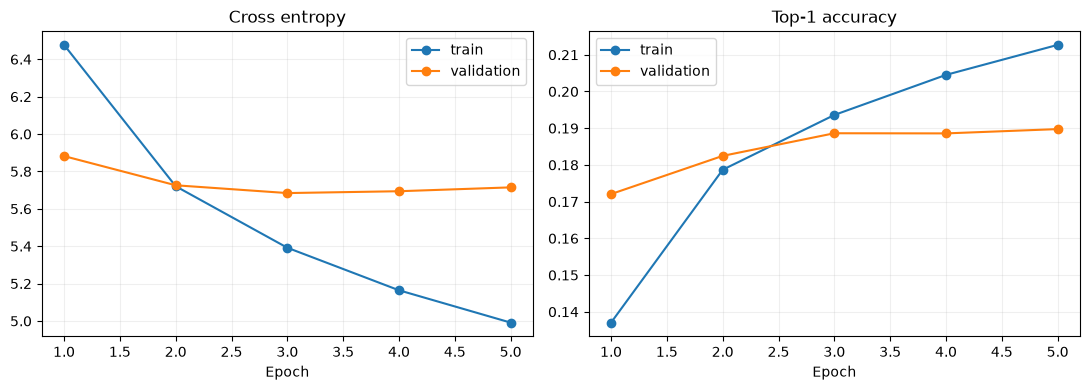

In [40]:
fig,axs=plt.subplots(1,2,figsize=(11,4))
for a,k1,k2,title in [(axs[0],'train_loss','val_loss','Cross entropy'),(axs[1],'train_top1','val_top1','Top-1 accuracy')]:
    a.plot([r['epoch'] for r in metrics],[r[k1] for r in metrics],label='train',marker='o')
    a.plot([r['epoch'] for r in metrics],[r[k2] for r in metrics],label='validation',marker='o')
    a.set(xlabel='Epoch',title=title);a.grid(alpha=.2);a.legend()
plt.tight_layout();fig.savefig(OUTPUTS_DIR/'training_curves.png',dpi=160,bbox_inches='tight');plt.show()

## 14. Test evaluation and generated-text evaluation

Test chỉ chạy sau khi đã chọn best checkpoint. Top-1/Top-5 tính trên **mỗi vị trí token**; test perplexity theo tập từ vựng và tiền xử lý trong notebook. Với sinh văn bản, đánh giá định tính bằng sự mạch lạc, lỗi cú pháp, lặp từ; tỷ lệ token duy nhất là một chỉ số mô tả đơn giản, không phải thước đo chất lượng hoàn chỉnh.

In [41]:
test_result=eval_model(model,test_dl)
print('TEST:',{k:round(v,4) for k,v in test_result.items()})
(OUTPUTS_DIR/'metrics.json').write_text(json.dumps({
    'dataset':DATASET,'config':CONFIG,'subset_token_budget':TOKEN_BUDGET,
    'best_validation_loss':best_val,'test':test_result,'training_history':metrics
},indent=2),encoding='utf8')
print('Đây là kết quả subset' if TOKEN_BUDGET['train'] is not None else 'Đây là kết quả corpus đầy đủ')

TEST: {'loss': 5.6388, 'top1': 0.1864, 'top5': 0.3709, 'perplexity': 281.1121}
Đây là kết quả subset


## 15. Next-word prediction and interactive text-generation demo

`predict_next` trả JSON phù hợp web: top-k với xác suất **gốc ở temperature=1**, OOV, normalized entropy, top-k mass, phần còn lại, độ dài context. `top1_probability` là điểm của mô hình trên từ vựng rút gọn, **không phải xác suất mô hình “đúng” đã hiệu chuẩn**. Khi prompt quá dài chỉ lấy `SEQ_LEN` token cuối. Prompt ngắn được xử lý theo đúng chiều dài thực của nó, không left-pad.

{
  "context": [
    "the",
    "history",
    "of",
    "the",
    "city"
  ],
  "truncated": false,
  "oov": [],
  "top_k": [
    {
      "word": "'s",
      "probability": 0.19438354671001434
    },
    {
      "word": "was",
      "probability": 0.11098098754882812
    },
    {
      "word": "is",
      "probability": 0.08284235000610352
    },
    {
      "word": ",",
      "probability": 0.06343334913253784
    },
    {
      "word": ".",
      "probability": 0.05120809003710747
    },
    {
      "word": "has",
      "probability": 0.0488063246011734
    },
    {
      "word": "of",
      "probability": 0.045101769268512726
    },
    {
      "word": "were",
      "probability": 0.029545476660132408
    },
    {
      "word": "council",
      "probability": 0.02718621864914894
    },
    {
      "word": "had",
      "probability": 0.026948891580104828
    }
  ],
  "top1_probability": 0.19438354671001434,
  "top_k_mass": 0.6804370041936636,
  "other_mass": 0.3195629958063364,
  "

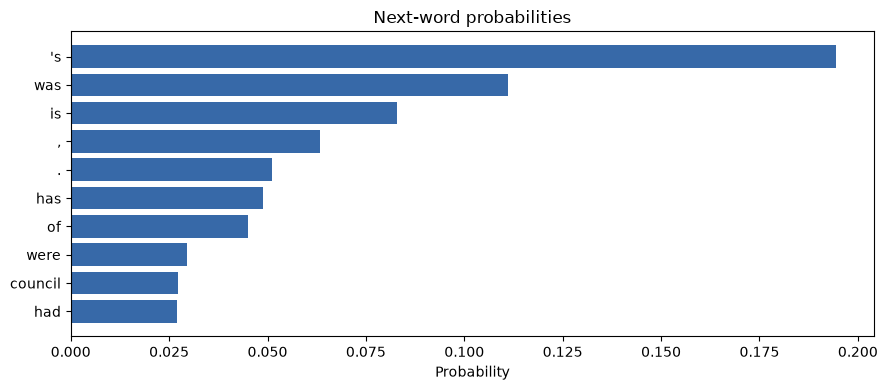

Text(value='the history of the city', description='Prompt:', layout=Layout(width='80%'))

Button(description='Predict', style=ButtonStyle())

Output()

In [42]:
def predict_next(prompt,top_k=10):
    tokens=tokenize(prompt)
    if not tokens:raise ValueError('Prompt cần ít nhất một từ.')
    used=tokens[-SEQ_LEN:]
    ids=torch.tensor([encode(used)],dtype=torch.long,device=device)
    with torch.inference_mode():
        logits,_=model(ids)
        probs=torch.softmax(logits[0,-1],dim=-1).cpu().numpy()
    probs[0]=0;probs/=probs.sum()
    order=np.argsort(probs)[::-1][:max(1,min(int(top_k),len(itos)-1))]
    items=[{'word':itos[int(i)],'probability':float(probs[i])} for i in order]
    nz=probs[probs>0];entropy=float(-(nz*np.log(nz)).sum())
    mass=float(sum(item['probability'] for item in items))
    return {'context':used,'truncated':len(tokens)>SEQ_LEN,'oov':[t for t in used if t not in stoi],
            'top_k':items,'top1_probability':items[0]['probability'],
            'top_k_mass':mass,'other_mass':max(0.,1-mass),'entropy_nats':entropy,
            'entropy_normalized':entropy/math.log(len(itos)-1),'vocab_size':len(itos),
            'probability_note':'Model probability over the reduced vocabulary, not calibrated correctness confidence.'}

example=predict_next('the history of the city',top_k=10)
print(json.dumps(example,indent=2))
fig,ax=plt.subplots(figsize=(9,4))
items=example['top_k'][::-1]
ax.barh([x['word'] for x in items],[x['probability'] for x in items],color='#3769a8')
ax.set(title='Next-word probabilities',xlabel='Probability');plt.tight_layout();fig.savefig(OUTPUTS_DIR/'topk_prediction.png',dpi=160,bbox_inches='tight');plt.show()

# Notebook interaction: widget nếu có, mặc định vẫn chạy mà không cần ipywidgets.
try:
    import ipywidgets as widgets
    from IPython.display import display,clear_output
    prompt_box=widgets.Text(value='the history of the city',description='Prompt:',layout=widgets.Layout(width='80%'))
    run_button=widgets.Button(description='Predict')
    ui_output=widgets.Output()
    def on_click(_):
        with ui_output:
            clear_output(wait=True)
            try:print(json.dumps(predict_next(prompt_box.value,10),indent=2))
            except ValueError as e:print(e)
    run_button.on_click(on_click);display(prompt_box,run_button,ui_output)
except ImportError:
    print('Muốn có widget: %pip install ipywidgets')

## 16. Autoregressive text generation

Mỗi bước: lấy logits cuối, chia temperature, giới hạn top-k cho sampling, lấy mẫu một token rồi thêm vào prompt. `temperature→0` gần greedy; temperature cao làm phân phối phẳng hơn. Nếu gặp `<unk>`, không thể khôi phục từ thật nên loại khỏi sampling. Dùng seed để tái lập. Kết quả có thể vô nghĩa do giới hạn RNN vanilla và số token train.

In [43]:
def generate_text(prompt, steps=30, temperature=1.0, sample_top_k=30, seed=42):
    if not 0 < temperature <= 3:
        raise ValueError("temperature cần thuộc (0,3]")
    if not 1 <= steps <= 200:
        raise ValueError("steps cần thuộc [1,200]")

    tokens = tokenize(prompt)
    if not tokens:
        raise ValueError("Prompt rỗng")

    generator = torch.Generator(device="cpu").manual_seed(seed)
    trace = []

    for _ in range(steps):
        ids = torch.tensor(
            [encode(tokens[-SEQ_LEN:])],
            dtype=torch.long,
            device=device
        )

        with torch.inference_mode():
            inference_logits = model(ids)[0][0, -1].cpu()

        # Tạo tensor mới ngoài inference_mode trước khi sửa giá trị tại chỗ.
        logits = inference_logits.clone() / temperature
        logits[:2] = -float("inf")  # Loại <pad> và <unk>

        values, indices = torch.topk(
            logits, min(int(sample_top_k), len(itos) - 2)
        )
        weights = torch.softmax(values, dim=0)
        idx = int(torch.multinomial(weights, 1, generator=generator))

        word = itos[int(indices[idx])]
        trace.append({
            "word": word,
            "sampling_probability": float(weights[idx])
        })
        tokens.append(word)

    return {
        "text": " ".join(tokens),
        "generated_tokens": trace,
        "temperature": temperature,
        "sample_top_k": sample_top_k
    }


out = generate_text("the history of the city", steps=35)
print(out["text"])
print(
    "Generated unique-token ratio:",
    round(
        len(set(x["word"] for x in out["generated_tokens"]))
        / len(out["generated_tokens"]),
        3
    )
)

(OUTPUTS_DIR / "generation_sample.json").write_text(
    json.dumps(out, indent=2),
    encoding="utf-8"
)

the history of the city 's original series was originally to be the most productive in the process of the hindu epic of parliament in this area , which was built in a tropical cyclone of 1 @,@ 000 men
Generated unique-token ratio: 0.8


3265

## 17. Effect of sequence length

So sánh ngữ cảnh 4, 8, 16, `SEQ_LEN` của **cùng mô hình đã train**: thay đổi prefix đưa vào suy luận để thấy phân phối thay đổi. Đây **không phải** thí nghiệm huấn luyện các mô hình độ dài chuỗi khác nhau và không chứng minh `SEQ_LEN` nào tối ưu. Nếu cần so sánh độ dài huấn luyện, chạy lại từ đầu với `SEQ_LEN` khác, giữ cùng split và ghi kết quả test sau khi chốt bằng validation.

In [44]:
long_prompt='the history of the city and the people who lived there over many years'
for n_context in [4,8,16,SEQ_LEN]:
    sub=' '.join(tokenize(long_prompt)[-n_context:])
    p=predict_next(sub,5)
    print(f"{n_context:2d} context tokens | top1={p['top_k'][0]['word']!r}, prob={p['top1_probability']:.3f}, entropy={p['entropy_nats']:.2f}")

 4 context tokens | top1='.', prob=0.247, entropy=3.22
 8 context tokens | top1='.', prob=0.236, entropy=3.32
16 context tokens | top1='.', prob=0.267, entropy=3.24
24 context tokens | top1='.', prob=0.267, entropy=3.24


## 18. Effect of temperature

Temperature điều chỉnh **lựa chọn token khi sinh**, không đổi trọng số và không làm mô hình “hiểu” tốt hơn. Sử dụng cùng seed để đối chiếu ở `0.5`, `1.0`, `1.5`; vì phân phối thay đổi, token lấy mẫu có thể khác mạnh.

In [45]:
for temp in [0.5,1.0,1.5]:
    result=generate_text('the history of the city',steps=20,temperature=temp,seed=7)
    print(f'temperature={temp}: {result["text"]}\n')

temperature=0.5: the history of the city 's main state of a period , and the 3rd battalion is in the late 20th century . the church

temperature=1.0: the history of the city 's main activity , but were released . this had been given that the ball , the dam to have

temperature=1.5: the history of the city have a three @-@ pound of fame ( which in july 2013 – 2000 in 2008 , 2013 was also



## 19. Error analysis

Lấy các vị trí dự đoán sai của test, ghi token đúng, top-5 và xác suất. Quan sát lỗi do `<unk>`, từ hiếm, tên riêng, dấu câu, phụ thuộc xa. Các ví dụ sai được chọn để phân tích sau đánh giá; không dùng chúng để chọn lại hyperparameter trên test.

In [46]:
def inspect_errors(loader,limit=8):
    findings=[];model.eval()
    with torch.inference_mode():
        for x,y in loader:
            logits,_=model(x.to(device));probs=torch.softmax(logits,dim=-1).cpu()
            for bi in range(len(x)):
                for ti in range(x.shape[1]):
                    truth=int(y[bi,ti]);top=probs[bi,ti].topk(5)
                    if int(top.indices[0])!=truth:
                        findings.append({'context':' '.join(decode(x[bi,max(0,ti-6):ti+1])),
                                         'truth':itos[truth],
                                         'top5':[(itos[int(i)],round(float(v),3)) for v,i in zip(top.values,top.indices)]})
                    if len(findings)>=limit:return findings
    return findings
for case in inspect_errors(test_dl):print(json.dumps(case,ensure_ascii=False))

{"context": "robert", "truth": "<unk>", "top5": [["bianco", 0.125], ["le", 0.037], ["shearman", 0.022], ["lester", 0.02], ["<unk>", 0.019]]}
{"context": "robert <unk>", "truth": "is", "top5": [[",", 0.355], ["<unk>", 0.119], ["(", 0.079], ["and", 0.076], [".", 0.063]]}
{"context": "robert <unk> is", "truth": "an", "top5": [["a", 0.17], ["the", 0.139], ["an", 0.035], ["<unk>", 0.031], ["in", 0.024]]}
{"context": "robert <unk> is an", "truth": "english", "top5": [["<unk>", 0.115], ["important", 0.033], ["\"", 0.016], ["actor", 0.01], ["estimated", 0.009]]}
{"context": "robert <unk> is an english", "truth": "film", "top5": [["<unk>", 0.043], ["@-@", 0.036], ["version", 0.029], [",", 0.021], ["channel", 0.016]]}
{"context": "robert <unk> is an english film ,", "truth": "television", "top5": [["and", 0.098], ["\"", 0.053], ["the", 0.048], ["who", 0.045], ["a", 0.038]]}
{"context": "<unk> is an english film , television", "truth": "and", "top5": [[",", 0.11], ["<unk>", 0.071], ["'s", 0.058],

## 20. Limitations of vanilla RNN and LSTM/GRU motivation

Vanilla RNN truyền gradient qua nhiều bước nên có thể gặp tiêu biến hoặc bùng nổ; clip gradient chỉ giúp hạn chế **bùng nổ**. Mô hình hiện tại reset hidden ở ranh giới mỗi cửa sổ; phạm vi ngữ cảnh huấn luyện trực tiếp bị giới hạn ở `SEQ_LEN`. LSTM bổ sung cell state cùng các cổng quên/nhập/xuất; GRU dùng cổng cập nhật/đặt lại. Chúng thường là hướng so sánh hợp lý khi cần phụ thuộc dài hơn, nhưng kết quả phải đo cùng dữ liệu và tokenization. WikiText-103 full cũng lớn hơn rất nhiều so với token budget mặc định.

## 21. Final summary and model export for a web demo

Lưu `models/best_rnn_state.pt` và `models/metadata.json` cho web; lưu `outputs/metrics.json`, biểu đồ và bản sinh mẫu cho báo cáo. `data/hf_cache` là cache của bộ dữ liệu tải về. Lưu `state_dict`, vocab, cấu hình và test metric. Web Flask/FastAPI cần tái dùng **chính xác** `clean_line`, `tokenize`, `WordRNN`, `itos/stoi` và checkpoint. `torch.load(...,weights_only=True)` và `model.eval()` khi phục vụ; không tải dữ liệu WikiText-103 trong mỗi request. Endpoint gợi ý: `POST /predict` trả JSON của `predict_next`; `POST /generate` trả text và trace. Biểu đồ top-k, top-k mass, entropy và bảng các bước sinh có thể lấy trực tiếp từ JSON. Không gọi `sampling_probability` là độ tin cậy dự đoán đúng: đó là xác suất sau temperature **và top-k truncation**.

In [47]:
metadata={'dataset':DATASET,'dataset_config':CONFIG,'language':'English',
          'subset_token_budget':TOKEN_BUDGET,'tokenizer':'NFC_lower_whitespace_v1',
          'vocab':itos,'seq_len':SEQ_LEN,'embed_dim':EMBED_DIM,'hidden_dim':HIDDEN_DIM,
          'seed':SEED,'train_windows':len(train_ds),'validation_windows':len(val_ds),'test_windows':len(test_ds),
          'best_validation_loss':best_val,'test_metrics':test_result,'history':metrics}
(MODELS_DIR/'metadata.json').write_text(json.dumps(metadata,ensure_ascii=False,indent=2),encoding='utf8')
loaded=json.loads((MODELS_DIR/'metadata.json').read_text(encoding='utf8'))
server_model=WordRNN(len(loaded['vocab']),loaded['embed_dim'],loaded['hidden_dim']).to(device)
server_model.load_state_dict(torch.load(CHECKPOINT,map_location=device,weights_only=True));server_model.eval()
with torch.inference_mode():
    assert server_model(torch.tensor([[stoi.get('the',1)]],device=device))[0].shape==(1,1,len(itos))
print('Saved:',CHECKPOINT,MODELS_DIR/'metadata.json',OUTPUTS_DIR/'metrics.json')

Saved: C:\Users\ADMIN\Downloads\Intelligent System\RNN\DATA\Plus\models\best_rnn_state.pt C:\Users\ADMIN\Downloads\Intelligent System\RNN\DATA\Plus\models\metadata.json C:\Users\ADMIN\Downloads\Intelligent System\RNN\DATA\Plus\outputs\metrics.json


### Sources

- [Salesforce WikiText dataset card](https://huggingface.co/datasets/Salesforce/wikitext) — source, configurations, splits, license.
- [PyTorch RNN API](https://docs.pytorch.org/docs/stable/generated/torch.nn.RNN.html) — RNN and tensor shapes.
- [PyTorch word language model example](https://github.com/pytorch/examples/tree/main/word_language_model) — RNN language modeling workflow.
- [PyTorch saving/loading models](https://docs.pytorch.org/tutorials/beginner/saving_loading_models.html) — state dict and inference loading.
- [Dive into Deep Learning BPTT](https://d2l.ai/chapter_recurrent-neural-networks/bptt.html) — temporal gradients and truncation.